# Scikit-learn for a Classification Task

In [1]:
import numpy as np
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

## Load Iris dataset

In [2]:
print("Loading the Iris dataset...")
iris = load_iris()

X = iris.data
y = iris.target

print(f"\nFeature Names: {iris.feature_names}")
print(f"Target Names: {iris.target_names}")
print(f"Unique labels in the dataset: {np.unique(y)}")
print(f"\nShape of features: {X.shape}")
print(f"Shape of labels: {y.shape}")

Loading the Iris dataset...

Feature Names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target Names: ['setosa' 'versicolor' 'virginica']
Unique labels in the dataset: [0 1 2]

Shape of features: (150, 4)
Shape of labels: (150,)


## Data processing and splitting

In [3]:
print("Splitting the dataset into training and testing sets...")
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"\nTraining set shape: features {X_train.shape}, labels {y_train.shape}")
print(f"Testing set shape: features {X_test.shape}, labels {y_test.shape}")

Splitting the dataset into training and testing sets...

Training set shape: features (120, 4), labels (120,)
Testing set shape: features (30, 4), labels (30,)


## Build and train the model

In [4]:
print("Compiling the model...")
model = RandomForestClassifier(random_state=42)

print("\nTraining the model...")
model.fit(X_train, y_train)

Compiling the model...

Training the model...


RandomForestClassifier(random_state=42)

## Evaluate the model

In [5]:
print("Evaluating the model on the test dataset...")
y_pred = model.predict(X_test)

Evaluating the model on the test dataset...


a) Accuracy

In [6]:
accuracy = accuracy_score(y_test, y_pred)

# Print the test accuracy as a percentage
print(f'Accuracy: {accuracy*100:.2f}%')


Accuracy: 100.00%


b) Confusion Matrix


Confusion Matrix:
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


Text(70.72222222222221, 0.5, 'True')

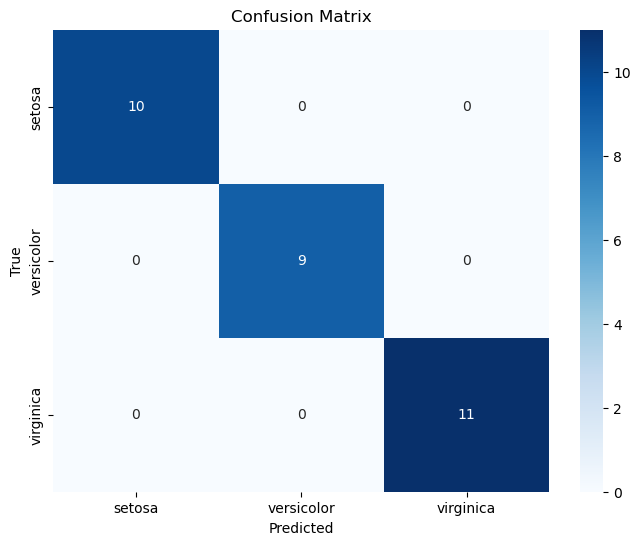

In [7]:

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

print(f"\nConfusion Matrix:\n{cm}")

# Visualizing the confusion matrix using seaborn heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('True')

c) Classification Report

In [8]:
# Generate classification report
report = classification_report(y_test, y_pred, target_names=iris.target_names)

print(f"\nClassification Report:\n{report}")


Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



## Summary

The Iris dataset contains only 150 samples with 4 numerical features, making it small and easy to process. While some classes are linearly separable, others have overlapping feature distributions, requiring a model that can capture both simple and complex decision boundaries. Random Forest is well-suited for this task as it combines multiple decision trees to model non-linear relationships effectively, while also being robust to overfitting on small datasets. Its ability to handle a mix of clear and subtle separations between classes makes it an ideal choice for the Iris classification problem.

### Overall Accuracy
The model achieved an accuracy of 1.0 (100%), meaning every single test sample was classified correctly. Out of the 30 samples in the test set, there were zero misclassifications. This indicates extremely strong performance.

### Confusion Matrix Analysis
All predictions fell exactly along the diagonal of the confusion matrix, meaning that every flower species (Setosa, Versicolor, and Virginica) was correctly predicted without error. No instances of one species were misclassified as another. This perfect separation suggests the Iris dataset’s features are highly discriminative.

### Classification Report
- Precision was 1.00 for all three species, meaning that whenever the model predicted a species, it was always correct.  
- Recall was also 1.00 for all species, meaning that every actual instance of each class was identified correctly.  
- F1-score, which balances precision and recall, was 1.00 for all species as well, indicating flawless classification performance.